# Logistic Regression

## Importing the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Importing the dataset

In [2]:
dataset = pd.read_csv('/content/placement.csv')

## Splitting the Fearures and the target

In [3]:
X = dataset.drop(columns='placed',axis=1)
y = dataset['placed']

In [4]:
print(X)

     cgpa  placement_exam_marks
0    7.19                  26.0
1    7.46                  38.0
2    7.54                  40.0
3    6.42                   8.0
4    7.23                  17.0
..    ...                   ...
995  8.87                  44.0
996  9.12                  65.0
997  4.89                  34.0
998  8.62                  46.0
999  4.90                  10.0

[1000 rows x 2 columns]


In [5]:
print(y)

0      1
1      1
2      1
3      1
4      0
      ..
995    1
996    1
997    0
998    1
999    1
Name: placed, Length: 1000, dtype: int64


<Axes: >

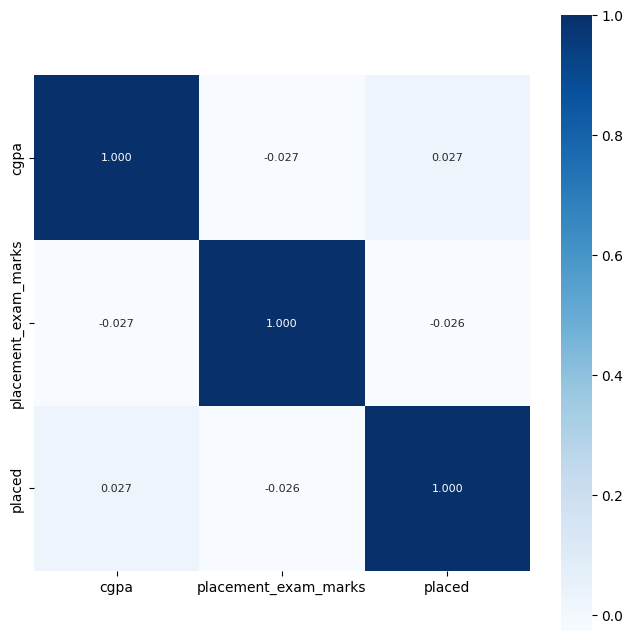

In [6]:
correlation = dataset.corr()
plt.figure(figsize = (8,8))
sns.heatmap(correlation, cbar=True, square=True, fmt='.3f',annot=True, annot_kws={'size':8}, cmap='Blues')

cbar=True: Displays the color bar on the side of the heatmap.

square=True: Ensures that each cell in the heatmap is square-shaped.

fmt='.1f': Formats the annotation text to one decimal place.

annot=True: Annotates each cell with the numeric value.

annot_kws={'size':8}: Sets the font size for the annotations.

cmap='Blues': Uses the 'Blues' colormap for the heatmap.

## Splitting the dataset into the Training set and Test set

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

In [8]:
print(X_train)

     cgpa  placement_exam_marks
253  6.98                  76.0
667  7.17                  54.0
85   6.03                  28.0
969  6.86                  41.0
75   6.77                  56.0
..    ...                   ...
835  6.67                  65.0
192  6.67                  38.0
629  8.15                  11.0
559  6.61                  58.0
684  8.02                  67.0

[750 rows x 2 columns]


In [ ]:
print(y_train)

In [ ]:
print(X_test)

In [ ]:
print(y_test)

## Training the Logistic Regression model on the Training set

In [9]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)

LogisticRegression(random_state=0)

## Predicting the Test set results

In [10]:
y_pred = classifier.predict(X_test)
# Directly reshape y_pred, assuming it is a numpy array
y_pred_array = y_pred.reshape(-1, 1)

# Convert y_test to a numpy array and reshape it, regardless of its original type
y_test_array = np.array(y_test).reshape(-1, 1)

# Concatenate arrays along the second axis (column-wise concatenation)
combined_array = np.concatenate((y_pred_array, y_test_array), axis=1)
print(combined_array)

[[0 1]
 [0 0]
 [0 0]
 [1 0]
 [1 0]
 [1 1]
 [0 0]
 [0 0]
 [1 0]
 [1 1]
 [0 1]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [1 0]
 [0 1]
 [0 1]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [1 1]
 [1 0]
 [1 1]
 [1 1]
 [0 1]
 [0 1]
 [1 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 1]
 [0 1]
 [0 0]
 [1 0]
 [0 0]
 [1 1]
 [0 1]
 [1 0]
 [1 0]
 [0 0]
 [0 1]
 [1 0]
 [1 0]
 [0 1]
 [1 1]
 [0 1]
 [0 0]
 [1 1]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [1 1]
 [0 0]
 [1 0]
 [0 0]
 [0 0]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [1 1]
 [1 1]
 [1 1]
 [0 1]
 [0 0]
 [1 0]
 [0 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 1]
 [0 1]
 [0 0]
 [0 1]
 [0 0]
 [0 1]
 [0 0]
 [1 0]
 [0 1]
 [0 1]
 [0 1]
 [1 0]
 [1 0]
 [0 0]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [1 0]
 [0 1]
 [0 1]
 [0 0]
 [1 0]
 [0 1]
 [0 1]
 [0 0]
 [1 0]
 [0 0]
 [1 0]
 [1 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 0]
 [0 1]
 [1 1]
 [1 0]
 [0 0]
 [0 0]
 [1 1]
 [0 1]
 [0 1]
 [1 1]
 [1 0]
 [0 0]
 [0 1]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [1 0]
 [1 1]

## Making the Confusion Matrix

In [11]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print(cm)
accuracy_score(y_test, y_pred)

[[76 51]
 [73 50]]


0.504

## Predicting a new result

In [16]:
prediction = classifier.predict(([[5.0,20]]))
print(prediction)

if (prediction[0]== 0):
  print('Not placed')
else:
  print('Placed')

[0]
Not placed


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
